
# 01 七因子投资：核心笔记

> **本章要解决的问题**：阿尔法越来越难找，为什么还有一批“因子”能长期赚钱？七个因子分别是什么？凭什么说一个因子是真的、不是数据挖出来的？为什么回测很漂亮的因子，发表几年后就不灵了？

## 本章导读

这是一本 0 基础读书笔记，对应 Berkin 与 Swedroe 的《Your Complete Guide to Factor-Based Investing》（2016），回答三个问题：**因子是什么、哪些值得信、普通人怎么用**。

全书的主线可以压成四句话：

1. 因子投资不是“选好公司”，而是**有纪律地超配某一类特征**（便宜、强势、高质量……）；
2. 不是所有“能赚钱的规律”都算因子——要过**五道门**：persistent（持续）、pervasive（普遍）、robust（稳健）、investable（可投资）、logically explainable（有逻辑）；
3. 因子会**衰减、拥挤、被成本吃掉**，回测收益要打折；
4. 对一人量化来说，正确姿势是：**先选 2–3 个低相关因子、看扣费后、别把回测当未来**。

代码部分用**合成数据**演示：先造七个因子 20 年的月度收益，再算累计净值、Sharpe、最大回撤、相关矩阵，最后比较单因子与多因子组合。**合成数据只用于演示方法，数字不代表真实市场。**

### 学习目标

- 给定“因子投资”这个词，能用自己的话说清它和买指数、选个股的区别。
- 给定七个因子清单，能说出每个因子的定义、经济逻辑、典型度量与失效场景。
- 给定一个候选因子，能用 persistent / pervasive / robust / investable / logically explainable 五条标准逐条追问。
- 给定一组因子收益，能算年化收益、波动、Sharpe、最大回撤与 t 值，并解释这些数字在筛选里的作用。
- 给定多个低相关因子，能说明为什么等权/风险平价组合的 Sharpe 可能高于单因子平均。
- 给定一个回测结果，能指出它需要打几折（衰减、拥挤、成本、容量），并写出一人量化的最小落地方案。

### 先修

会看收益率、波动率、相关系数；知道“回测”和“样本外”的基本含义；不需要编程基础，代码能跑通、会看表格即可。前 45 本的 03（单因子报告）、04（线性代数）、13（多因子组合）、20（多重检验）、37（工具链）可以当参考。

## 在量化研究中的位置

- **谁用**：个人投资者、FOF/资产配置、策略研究员、想从“选股”转向“配置”的人。
- **输入**：因子定义与历史收益、不同市场/品种的复制数据、成本与容量假设。
- **输出**：候选因子清单、五条标准的检验结果、多因子组合方案、可落地的执行约束。
- **在流程的哪一步**：在“读论文/看书”和“写代码做回测”之间；它决定你研究什么、为什么研究。
- **失败模式**：把数据挖掘当因子、只看回测收益不看逻辑、忽略发表后衰减与成本、单因子重仓。
- **最小工作流**：列因子 → 过五道门 → 算单因子绩效 → 看相关性 → 组多因子 → 扣费与样本外复核。

### 环境准备



In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("pandas", pd.__version__, "| numpy", np.__version__)


pandas 3.0.2 | numpy 2.4.4



## 1. 因子投资是什么

先打个比方。买指数，是把钱平均撒给整个市场，赚的是“市场平均”的钱；选个股，是赌自己比市场更懂某几家公司。**因子投资是第三条路**：不挑公司，挑“特征”。

比如“价值因子”：把全市场股票按估值（市盈率、市净率）排序，买入最便宜的一批、卖出（或低配）最贵的一批。它不关心具体公司，只关心“便宜”这个特征；类似地，动量买“过去涨得好”的，质量买“盈利稳定、负债低”的。

因子组合通常有两种做法：

1. **多空组合**：做多高分组、做空低分组，得到剔除市场涨跌的“纯因子”收益；
2. **只做多（smart beta）**：只买高分组，收益里仍带着市场 beta，但更贴近普通投资者能落地的产品。

因子为什么能赚钱？学界有两类解释，常常同时存在：

- **风险补偿**：承担了某种让人不舒服的风险（小公司流动性差、价值股可能基本面恶化），所以长期要有额外回报；
- **行为偏差**：投资者系统性犯错（追涨杀跌、对坏消息反应不足），价格偏离后慢慢修正，因子赚的是“纠错”的钱。

这两条解释决定了“有经济逻辑”为什么是五条标准之一：如果连“谁在亏钱、为什么亏”都讲不清，这个因子大概率是数据挖出来的。

因子投资和 alpha 的区别也在这里：**因子是公开的、可解释的、容量大的风险溢价；alpha 是私有的、易衰减的信息优势**。对个人做量化，因子是更现实的起点。

---

## 2. 七个因子：定义、逻辑、度量、失效

Berkin 与 Swedroe 把值得长期配置的因子收成七个：前六个是股票/跨资产的风格溢价，第七个 carry 是套息溢价。

| 因子 | 定义 | 经济逻辑 | 典型度量 | 失效场景 |
|---|---|---|---|---|
| 市场 beta | 承担股票市场整体风险获得的溢价 | 风险补偿：股市长期向上，但要承受回撤 | 市场收益 − 无风险利率 | 长期横盘、估值过高、危机 |
| 规模 SMB | 小市值公司长期跑赢大市值 | 小公司风险高、流动性差、关注少 | 小市值组 − 大市值组收益 | 小盘流动性危机、风格切换 |
| 价值 HML | 便宜股票跑赢贵股票 | 均值回归 + 风险补偿 + 过度反应 | B/P、E/P、CF/P 分组多空 | 价值陷阱、成长风格长期占优 |
| 动量 MOM | 过去涨的继续涨、跌的继续跌 | 反应不足、趋势跟随、资金流 | 过去 12 个月（剔除最近 1 月）收益 | 剧烈反转、危机中“动量崩溃” |
| 质量 QMJ/RMW | 高盈利、低负债、稳定的公司跑赢 | 质量溢价、避险需求、应计异象 | ROE、毛利率、应计、杠杆 | 质量定义分歧、拥挤 |
| 期限 TERM | 长期债券相对短期债券的溢价 | 久期风险补偿 | 长债收益 − 短债收益 | 加息周期、曲线倒挂 |
| carry | 持有高 carry 资产的套息收益 | 展期收益、套息交易、风险补偿 | 期货近远月价差、利率差、股息率 | carry 崩溃（如瑞郎脱钩）、拥挤 |

几点补充：

- **市场 beta 是唯一的“beta”**，其余六个是风格/跨资产溢价；所以也叫“1 个 beta + 6 个溢价”。
- **期限与 carry 不只属于股票**：TERM 在债券上最典型，carry 在商品（展期）、外汇（利差）、债券（骑乘）上都存在。
- **A 股与国内商品要单独验证**：规模、价值在 A 股历史上有效但波动大，动量偏弱；商品期货的期限结构、carry 反而是更常用的因子。
- **不是因子**：书里专门说明，股息/分红不是独立因子——高股息往往只是价值、低波、质量的代理；判断“新因子”前，先问它是不是已有因子的影子。
- **规模是七个里最弱的**：书末附录专门“重新评估 size premium”；小市值溢价对样本、流动性、退市/壳价值很敏感，别把它当稳定印钞机。

### 2.1 代码：合成七个因子 20 年的月度收益

为了后面能算 Sharpe、相关矩阵和组合，我们先“造”一份数据：七个因子、240 个月（20 年），每个因子有自己的年化收益、波动和彼此的相关性。**这是教学数据，不是真实市场。**



In [2]:

names = ["市场 beta", "规模 SMB", "价值 HML", "动量 MOM", "质量 QMJ", "期限 TERM", "carry CARRY"]
ann_mu = np.array([0.065, 0.025, 0.045, 0.055, 0.040, 0.020, 0.030])
ann_vol = np.array([0.155, 0.115, 0.135, 0.125, 0.105, 0.055, 0.075])
corr = np.array([
    [1.00, 0.40, 0.30, -0.30, 0.30, -0.15, -0.10],
    [0.40, 1.00, 0.35, 0.10, 0.25, 0.00, 0.00],
    [0.30, 0.35, 1.00, -0.45, 0.40, -0.05, 0.05],
    [-0.30, 0.10, -0.45, 1.00, -0.20, 0.00, 0.00],
    [0.30, 0.25, 0.40, -0.20, 1.00, 0.00, 0.00],
    [-0.15, 0.00, -0.05, 0.00, 0.00, 1.00, 0.50],
    [-0.10, 0.00, 0.05, 0.00, 0.00, 0.50, 1.00],
])
T = 240
rng = np.random.default_rng(3)
L = np.linalg.cholesky(corr)
z = rng.normal(size=(T, len(names))) @ L.T
rets = pd.DataFrame(ann_mu / 12 + (ann_vol / np.sqrt(12)) * z, columns=names,
                    index=pd.period_range("2004-01", periods=T, freq="M").to_timestamp("M"))
print("月度收益矩阵：", rets.shape, "（", T, "个月 = 20 年）")
print(rets.head(3).round(4).to_string())
print("设定平均两两相关：", round(float(corr[np.triu_indices(7, 1)].mean()), 3))


月度收益矩阵： (240, 7) （ 240 个月 = 20 年）
            市场 beta  规模 SMB  价值 HML  动量 MOM  质量 QMJ  期限 TERM  carry CARRY
2004-01-31   0.0967 -0.0486  0.0176 -0.0630  0.0026  -0.0089      -0.0435
2004-02-29  -0.0050 -0.0273  0.1118 -0.0486  0.0179  -0.0049      -0.0079
2004-03-31  -0.0418 -0.0238  0.0049 -0.0022  0.0225   0.0015       0.0036
设定平均两两相关： 0.067



**读数**：表格是 240 行 × 7 列的月度收益，每行一个月。七个因子的“设定”年化收益从 2% 到 6.5%、波动从 5.5%（期限）到 15.5%（市场）。真实数据里这些数字会随样本期大幅变化，所以**看因子不能只看一段时间的均值，还要看 t 值和回撤**。

---

## 3. 五条筛选标准：怎么判断“是不是真因子”

市面上的“因子”很多是数据挖掘。Berkin 与 Swedroe 用五条标准过滤，可以理解成**五道门**：

| 标准 | 中文 | 检验问题 | 怎么看 |
|---|---|---|---|
| persistent | 持续 | 这个溢价在不同时间段、不同子样本里都还在吗？ | 滚动 10 年收益、样本内外对比、发表后是否衰减 |
| pervasive | 普遍 | 换个市场、换个品种还存在吗？ | 美股/A 股/欧洲/期货多市场复制 |
| robust | 稳健 | 换个度量、换种分组方法还成立吗？ | PE 换 PB、换分位数、换权重、换持有期 |
| investable | 可投资 | 扣掉成本、考虑容量和做空约束后还有吗？ | 净收益、换手、容量、交易可行性 |
| logically explainable | 有逻辑 | 能讲清“谁在亏钱、为什么”吗？ | 风险补偿或行为偏差解释 |

五条不是五个优点，而是**五个否决项**：任何一条明显不过关，都要怀疑是数据挖掘。实战顺序通常是：先看逻辑（讲不讲得通），再看持续与普遍（是不是只在某一段、某个市场有效），再看稳健（是不是只有某一种度量有效），最后看扣费后还剩多少。

### 3.1 代码：用数字看单因子

五条标准里，“持续”“稳健”“可投资”最终都要落到数字上：



              年化收益   年化波动  Sharpe   最大回撤    t 值     胜率
市场 beta      0.084  0.154   0.598 -0.455  2.676  0.567
规模 SMB       0.041  0.114   0.406 -0.410  1.817  0.554
价值 HML       0.109  0.136   0.830 -0.292  3.711  0.592
动量 MOM       0.025  0.114   0.269 -0.373  1.205  0.550
质量 QMJ       0.085  0.103   0.846 -0.192  3.785  0.592
期限 TERM      0.012  0.052   0.263 -0.198  1.176  0.546
carry CARRY  0.034  0.074   0.487 -0.243  2.177  0.571


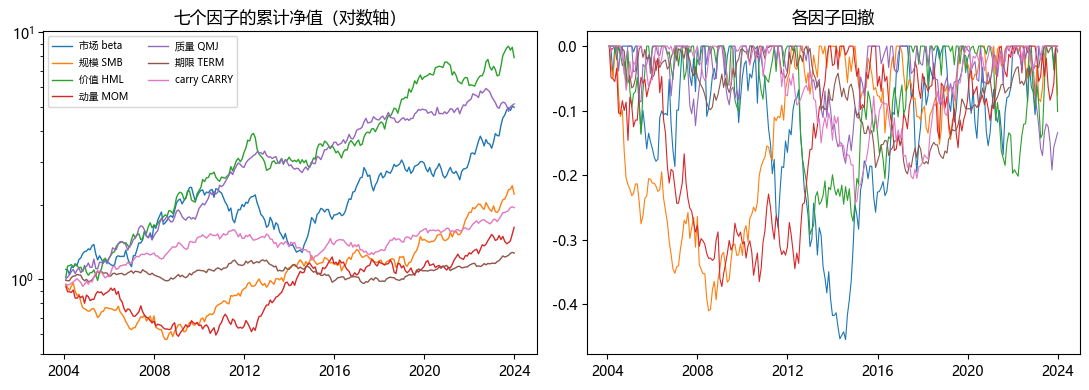

In [3]:

def perf(r):
    nav = (1 + r).cumprod()
    return {"年化收益": nav.iloc[-1] ** (12 / len(r)) - 1, "年化波动": r.std(ddof=1) * np.sqrt(12),
            "Sharpe": r.mean() / r.std(ddof=1) * np.sqrt(12),
            "最大回撤": (nav / nav.cummax() - 1).min(),
            "t 值": r.mean() / (r.std(ddof=1) / np.sqrt(len(r)))}


table = pd.DataFrame({n: perf(rets[n]) for n in names}).T
table["胜率"] = [(rets[n] > 0).mean() for n in names]
print(table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
navs = (1 + rets).cumprod()
for n in names:
    axes[0].plot(navs.index, navs[n], linewidth=1, label=n)
axes[0].set_yscale("log")
axes[0].set_title("七个因子的累计净值（对数轴）")
axes[0].legend(fontsize=7, ncol=2)
for n in names:
    axes[1].plot(navs.index, navs[n] / navs[n].cummax() - 1, linewidth=0.8)
axes[1].set_title("各因子回撤")
plt.tight_layout()
plt.show()



**读数**（合成数据）：七个因子的年化收益 1.2%–10.9%，Sharpe 0.26–0.85，最大回撤 −19% 到 −46%。t 值更有意思：质量 3.79、价值 3.71、市场 2.68、carry 2.18 都过 2；但动量 1.21、期限 1.18 在 20 年样本里并不显著。**这就是五条标准的现实版：收益高不等于可信，20 年也未必够。**

**读表要点**：年化收益会被少数暴涨月份误导，要配合 Sharpe（每单位波动换多少收益）与最大回撤（最难受时亏多少）一起看；t 值约 2 以上才算统计上站得住；胜率不是越高越好（动量常是“胜率一般、盈亏比高”）。

**常见错误**：

1. 只看年化收益排名，选到“高收益高回撤”的因子，实际拿不住。
2. 把 20 年样本的 t=1.2 当成“因子无效”——也可能只是样本不够长。
3. 用全样本算 Sharpe，却拿它预测未来（没有样本外）。

---

## 4. 发表之后：衰减、拥挤、成本、容量

书里有一章专门讲“因子会衰减”，这是最容易被回测骗的地方。

### 4.1 发表后衰减

学术研究发表后，因子收益往往会下降。McLean 与 Pontiff（2016）统计了 97 个异象，发现样本外收益平均比样本内低约 26%，发表后相对样本内低约 58%。原因：研究者在同一份历史数据上反复挖，样本内天然偏乐观；发表后资金涌入，把价格提前推到“合理”；成本与做空约束让纸面收益难以实现。

### 4.2 拥挤

“拥挤”指太多资金用相似的因子、相似的股票池、相似的调仓时点。征兆：因子与市场风格的相关性突然上升；回撤集中出现（大家都在减仓）；估值差、价差被压到历史极值。2007 年 8 月的“量化地震”就是典型：多家量化基金同时去杠杆、相关性骤升、回撤放大。

### 4.3 成本与容量

- **成本**：换手 × 单边成本。动量、小市值这类高换手因子，毛利可能被成本吃掉一半；
- **容量**：资金越大，冲击成本越高，因子收益越难维持；小市值尤其明显——论文里的小盘股，实盘可能根本买不到量。

**跟踪误差后悔**（Appendix A）：因子长期跑输市场时，投资者容易在最低点放弃；组合跟踪误差越大，这种“后悔”越强。个人也要预设“跑输多久、多少”的容忍度，否则策略没失效，人先失效。

**估算规则**：先算毛收益，再减“换手 × 成本”，再打“发表后折扣”，剩下的才是能指望的净收益；没扣费的 Sharpe 只是上限。

---



## 5. 多因子：分散化是“唯一接近免费午餐”的东西

单因子的 Sharpe 只有 0.26–0.85，还伴随 −19% 到 −46% 的回撤，怎么拿得住？答案是**把低相关因子组合起来**。

数学很直观：两个 Sharpe 都是 0.5、相关性为 0 的因子各配一半，组合收益是平均，波动却因“不同步”而下降，Sharpe 升到约 0.7。因子越多、相关越低，提升越明显——**多因子不承诺更高收益，但能在收益不怎么降的情况下降波动、降回撤，从而提升 Sharpe**。

常见三种配置方法：

| 方法 | 权重怎么定 | 优点 | 缺点 |
|---|---|---|---|
| 等权 | 每个因子 1/N | 简单、不依赖估计 | 高波动因子风险占比过大 |
| 逆波动 | 权重 ∝ 1/波动率 | 让各因子风险贡献接近 | 忽略相关性 |
| 风险平价 | 让每个因子的风险贡献相等 | 风险最均衡 | 需要协方差估计，可能不稳定 |

注意：**分散化不等于对冲**。危机时因子相关性一起上升，平时分散的组合可能同时回撤；多因子降低的是“平时”波动，不是尾部风险。

### 5.1 代码：相关矩阵与热图



             市场 beta  规模 SMB  价值 HML  动量 MOM  质量 QMJ  期限 TERM  carry CARRY
市场 beta         1.00    0.41    0.31   -0.27    0.28    -0.12        -0.10
规模 SMB          0.41    1.00    0.35    0.14    0.25     0.05         0.02
价值 HML          0.31    0.35    1.00   -0.44    0.28    -0.06        -0.00
动量 MOM         -0.27    0.14   -0.44    1.00   -0.06     0.00         0.05
质量 QMJ          0.28    0.25    0.28   -0.06    1.00    -0.00         0.04
期限 TERM        -0.12    0.05   -0.06    0.00   -0.00     1.00         0.50
carry CARRY    -0.10    0.02   -0.00    0.05    0.04     0.50         1.00
样本平均两两相关： 0.078


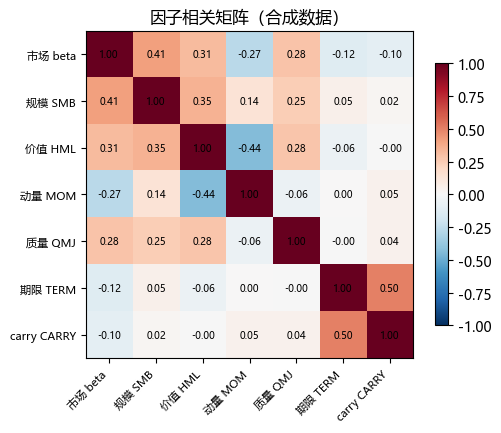

In [4]:

corr_real = rets.corr()
print(corr_real.round(2).to_string())
avg_corr = corr_real.values[np.triu_indices(len(names), 1)].mean()
print("样本平均两两相关：", round(float(avg_corr), 3))
fig, ax = plt.subplots(figsize=(5.4, 4.4))
im = ax.imshow(corr_real.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{corr_real.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("因子相关矩阵（合成数据）")
plt.tight_layout()
plt.show()



**读数**：样本平均两两相关约 0.078——这是为了教学刻意调低的。真实市场里权益类因子之间的平均相关常在 0.2–0.4，分散化效果会弱一些，但方向不变。注意几个**负相关**：价值与动量 −0.44、市场与动量 −0.27，这正是组合能降波动的来源；而期限与 carry 正相关 0.50，它们算“同一族”，不该当成两个独立分散源。

### 5.2 代码：等权、逆波动、风险平价



In [5]:

from scipy.optimize import minimize

cov = rets.cov().values
vols = np.sqrt(np.diag(cov))
w_ew = np.ones(len(names)) / len(names)
w_iv = (1 / vols) / (1 / vols).sum()


def risk_parity(cov):
    n = cov.shape[0]

    def obj(w):
        var = w @ cov @ w
        rc = w * (cov @ w) / var
        return float(((rc - 1.0 / n) ** 2).sum())

    res = minimize(obj, np.ones(n) / n, method="SLSQP",
                   bounds=[(1e-6, 1.0)] * n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    return res.x


w_rp = risk_parity(cov)
port = pd.DataFrame({"等权": rets.to_numpy() @ w_ew, "逆波动": rets.to_numpy() @ w_iv,
                     "风险平价": rets.to_numpy() @ w_rp}, index=rets.index)
ptable = pd.DataFrame({c: perf(port[c]) for c in port.columns}).T
print(ptable.round(3).to_string())
print(pd.DataFrame({"等权": w_ew, "逆波动": w_iv, "风险平价": w_rp}, index=names).round(3).to_string())


      年化收益   年化波动  Sharpe   最大回撤    t 值
等权    0.06  0.051   1.170 -0.059  5.232
逆波动   0.05  0.043   1.154 -0.048  5.163
风险平价  0.05  0.041   1.205 -0.045  5.388
                等权    逆波动   风险平价
市场 beta      0.143  0.088  0.091
规模 SMB       0.143  0.119  0.079
价值 HML       0.143  0.099  0.111
动量 MOM       0.143  0.118  0.181
质量 QMJ       0.143  0.131  0.110
期限 TERM      0.143  0.263  0.264
carry CARRY  0.143  0.182  0.166



**读数**：等权组合年化 6.0%、波动 5.1%、Sharpe 1.17、最大回撤 −5.9%；逆波动波动更低（4.3%），Sharpe 1.15；风险平价 Sharpe 最高（1.21）、回撤最小（−4.5%）。三种方法都比单因子好一大截——**单因子 Sharpe 均值只有 0.53，组合直接翻倍**。

看权重：逆波动和风险平价把期限（波动 5.2%）配到 26% 左右，把市场（波动 15.4%）压到 9%；等权则强制每个 14.3%。这说明“等权”不是中性的，它让高波动因子承担了更多风险。

**常见错误**：

1. 只看组合收益，不看风险来源——等权组合的收益可能被高波动因子主导。
2. 用全样本协方差算风险平价，未来相关性一变，权重就漂移。
3. 把“低相关”当成“危机时也不相关”；危机中相关性会跳升。

---

## 6. 对“一人量化”的三条建议

书虽写给机构，但个人做量化更该读——最容易犯的错就是“把回测当未来”。三条建议：

### 6.1 先选 2–3 个低相关、逻辑清楚、能拿到数据的因子

不要一上来追“机器学习挖出的神秘因子”。个人能长期跑下去的往往是**逻辑简单、数据便宜、换手不高、和其他因子低相关**的组合，比如“价值 + 动量 + carry”；用五条标准逐条问一遍，过不了“逻辑”和“可投资”的先放弃。

### 6.2 只信扣费后的数字

回测里的毛利要减三类成本：

1. **显性成本**：手续费、税费、融券费；
2. **隐性成本**：买卖价差、冲击成本（资金越大越明显）；
3. **机会成本**：停牌、涨跌停、无法成交。

把换手和成本写进回测，再打个“发表后折扣”，剩下的才是可能实现的收益。

### 6.3 别把 backtest 当未来

回测是“在历史上检验逻辑”，不是“预测未来”。至少做三件事：**样本外**（留最后几年不碰，只做最终检验）、**看衰减**（分前后两段、看子样本是否还成立）、**记录假设**（因子定义、数据版本、成本参数写进 manifest，见第 38 章）。

### 6.4 代码：单因子 vs 多因子、扣费与衰减



In [6]:

single_vol = table["年化波动"]
print("单因子平均年化波动", round(float(single_vol.mean()), 3),
      "| 等权组合", round(float(ptable.loc["等权", "年化波动"]), 3),
      "| 波动下降", f"{(1 - ptable.loc['等权', '年化波动'] / single_vol.mean()):.1%}")
print("单因子 Sharpe 均值", round(float(table["Sharpe"].mean()), 3),
      "| 最好", round(float(table["Sharpe"].max()), 3),
      "| 等权组合", round(float(ptable.loc["等权", "Sharpe"]), 3))
print("单因子最大回撤中位数", f"{table['最大回撤'].median():.1%}",
      "| 等权组合", f"{ptable.loc['等权', '最大回撤']:.1%}")

fee_single, fee_multi = 0.005, 0.008
net_single = rets - fee_single / 12
net_ew = port["等权"] - fee_multi / 12
net_single_sharpe = net_single.mean() / net_single.std(ddof=1) * np.sqrt(12)
print("扣费后 Sharpe：单因子均值", round(float(net_single_sharpe.mean()), 3),
      "| 等权组合", round(float(net_ew.mean() / net_ew.std(ddof=1) * np.sqrt(12)), 3))

rets_decay = rets.copy()
rets_decay.iloc[120:] = rets_decay.iloc[120:] - (ann_mu / 2) / 12
ew_decay = rets_decay.to_numpy() @ w_ew
print("发表后收益减半：等权组合 Sharpe 从", round(float(ptable.loc["等权", "Sharpe"]), 3),
      "降到", round(float(ew_decay.mean() / ew_decay.std(ddof=1) * np.sqrt(12)), 3))


单因子平均年化波动 0.107 | 等权组合 0.051 | 波动下降 52.0%
单因子 Sharpe 均值 0.529 | 最好 0.846 | 等权组合 1.17
单因子最大回撤中位数 -29.2% | 等权组合 -5.9%
扣费后 Sharpe：单因子均值 0.476 | 等权组合 1.014
发表后收益减半：等权组合 Sharpe 从 1.17 降到 0.977



**读数**：七个单因子平均波动 10.7%，等权组合只有 5.1%，**波动下降 52%**；Sharpe 从均值 0.53 提升到 1.17；最大回撤中位数从 −29.2% 降到组合的 −5.9%。扣费（单因子 0.5%/年、多因子 0.8%/年）后，单因子 Sharpe 均值降到 0.476，组合仍有 1.014——**分散化的效果没有被费用吃掉**。再做一次“发表后收益减半”的压力测试：等权组合 Sharpe 从 1.17 降到 0.977，依然高于大多数单因子。这就是多因子的价值：**它让“打折后的未来”仍然可接受**。

**常见错误**：

1. 用单因子最好那个的 Sharpe 和组合比——事前你并不知道哪个最好。
2. 忘扣费，或者只扣显性手续费。
3. 把“收益减半”当作最坏情况——实际衰减可能更久、更隐蔽。

---

## 7. 附录：低波动、时序动量、违约因子

书里还讨论了三个“编外”因子：

- **低波动**：低波动股票长期收益不输高波动股票、Sharpe 更高，解释包括“杠杆约束”和“彩票偏好”；它和“价值”有重叠，在 A 股要小心小盘与流动性影响。
- **时序动量**：每个资产和**自己的过去**比：过去 N 个月涨就做多、跌就做空；Moskowitz 等（2012）在股票、债券、商品、外汇上都发现了它，和截面动量不同。
- **违约因子**：低评级公司债相对高评级的溢价，本质是信用风险补偿；它和股票 beta、期限有相关性，配置时要看是否被其他因子解释。

这三个不一定要单独配，但值得知道：**因子的边界一直在扩张，判断标准还是那五条**。

---

## 本章小结

### 一张表

| 主题 | 一句话 |
|---|---|
| 因子投资 | 有纪律地超配某类特征，不是选个股 |
| 七个因子 | 市场 beta + 规模、价值、动量、质量、期限、carry |
| 五条标准 | persistent、pervasive、robust、investable、logically explainable |
| 衰减 | 发表后收益平均下降，回测要打折 |
| 拥挤 | 相关性上升、回撤集中，是因子失效的征兆 |
| 多因子 | 低相关 → 降波动、降回撤、提 Sharpe |
| 一人量化 | 2–3 个低相关因子、扣费后、样本外 |

### 八句话

1. 因子投资是“用纪律替代选股”。
2. 市场 beta 之外，还有六类风格/跨资产溢价。
3. 单因子先看 t 值和回撤，不只看收益。
4. 五条标准是五道门，缺一道就要怀疑数据挖掘。
5. 发表后收益会衰减，回测数字要打折。
6. 拥挤时因子会一起回撤，相关性上升。
7. 多因子分散化能在收益不怎么降的情况下降波动。
8. 一个人做量化：2–3 个低相关因子、扣费后、样本外。

---

## 本章习题

**1.** 因子投资与“买指数”“选个股”的本质区别是什么？

**2.** 七个因子分别是什么？哪一个是“beta”，哪些是“溢价”？

**3.** “persistent”和“robust”分别检验什么？为什么它们是两道不同的门？

**4.** 为什么一个 Sharpe 0.5 的因子，多个低相关因子等权组合后 Sharpe 可能超过 1？

**5.** 发表后因子收益为什么会衰减？至少说出两个原因。

**6.** 什么是因子拥挤？有哪三个征兆？

**7.** 为什么“扣费后”的收益才是真收益？成本至少包括哪三类？

**8.** 如果你只有 20 万资金、每周只能调仓一次，会选哪 2–3 个因子？说明理由。

<details><summary>参考答案</summary>

**1.** 买指数赚市场平均；选个股赌自己比市场更懂公司；因子投资不挑公司，只按特征分组，有纪律地超配/低配某类特征。

**2.** 市场 beta（唯一的 beta）、规模 SMB、价值 HML、动量 MOM、质量 QMJ/RMW、期限 TERM、carry；其中后六个是风格或跨资产溢价。

**3.** persistent 检验“时间上是否持续”（不同子样本、发表后是否还在）；robust 检验“度量/构造是否稳健”（换指标、换分组、换权重是否还成立）；一个管时间维度，一个管设定维度。

**4.** 组合收益是成分的加权平均，但波动会因低相关而下降（$\sigma_p^2=\sum w_i^2\sigma_i^2+\sum_{i\ne j}w_iw_j\sigma_i\sigma_j\rho_{ij}$，$\rho<1$ 时交叉项变小），Sharpe = 收益/波动因此上升。

**5.** 研究者反复挖历史数据导致样本内偏乐观；发表后资金涌入把价格推到合理；交易成本与做空约束让纸面收益难实现；拥挤导致回撤放大。

**6.** 太多资金用相似因子、相似股票池、相似调仓时点。征兆：因子间相关性突然上升；回撤集中出现；估值差/价差被压到历史极值。

**7.** 显性成本（手续费/税费/融券费）、隐性成本（价差/冲击）、机会成本（停牌/涨跌停/无法成交）；不扣费的回测只是理论上限。

**8.** 开放题。合理思路：选逻辑清楚、数据便宜、换手低的因子，如“价值 + 质量”或“价值 + carry”；只用 2–3 个是为了降低相关性不足带来的集中风险，同时匹配每周调仓的低频节奏。

</details>

---

## 参考资料

- **原书**：Berkin, A. L. & Swedroe, L. E. *Your Complete Guide to Factor-Based Investing: The Way Smart Money Invests Today*. BAM Alliance Press, 2016。
- Fama, E. F. & French, K. R. "Common Risk Factors in the Returns on Stocks and Bonds", *Journal of Financial Economics*, 1993；以及 "A Five-Factor Asset Pricing Model", 2015。
- Jegadeesh, N. & Titman, S. "Returns to Buying Winners and Selling Losers", *Journal of Finance*, 1993。
- Carhart, M. "On Persistence in Mutual Fund Performance", *Journal of Finance*, 1997。
- Asness, C., Moskowitz, T. & Pedersen, L. H. "Value and Momentum Everywhere", *Journal of Finance*, 2013。
- Koijen, R., Moskowitz, T., Pedersen, L. H. & Vrugt, E. "Carry", *Journal of Financial Economics*, 2018。
- McLean, R. D. & Pontiff, J. "Does Academic Research Destroy Stock Return Predictability?", *Journal of Finance*, 2016。
- Moskowitz, T., Ooi, Y. H. & Pedersen, L. H. "Time Series Momentum", *Journal of Financial Economics*, 2012。
- 课程交叉阅读：第 03 章（单因子报告）、第 06 章（线性代数与重复信息）、第 12 章（多因子组合）、第 29 章（多重检验）、第 37 章（工具链）、advanced/07（常见因子与标签工程）。
